# Milestone 2 — KonIQ-10k image quality regression

**Task:** predict the released continuous MOS (0–100) from one RGB photograph.
This milestone uses fully connected PyTorch networks rather than the ResNet
proposed in Milestone 1, to meet the MLP assignment.

This notebook imports reusable classes and functions from `src/mlp_data.py`,
`src/mlp_models.py`, `src/mlp_training.py`, and `src/run_milestone2.py`.
Keep the repository folders together, set the dataset paths, and run all cells in order. Tables and conclusions are calculated from real runs; no results are
pre-filled. A full run trains 14 models (9 grid + 4 learning rates + 1 deep).

## Protocol and rubric decisions

- This is **regression**: class samples, label encoding, and classification
  stratification are not applicable. Show low/middle/high MOS training examples.
  The reusable splitting function supports `labels=` for stratified classification.
- Preserve the authors' **2,015 test images**. Pool the 7,058 training and 1,000
  validation images, then split 80/20: **6,446 training / 1,612 validation**.
  This explicitly changes the Milestone 1 validation protocol to meet this
  assignment. Without predefined splits, the utility uses overall 64/16/20.
- Fit RGB channel mean/std and MOS mean/std **only on the final training set**.
  Never use human rating proportions, SD, or rating counts as features.
- Select settings and epochs by maximum validation **SROCC**, consistent with
  the project objective; lower validation RMSE breaks ties. Report MAE and RMSE
  in original MOS units. Do not compare raw values of different loss functions.
- The test set is evaluated only after all selection. A single fixed seed makes
  this a controlled course comparison, not a statistical significance study.


**Setup:** install `torch`, `numpy`, `pandas`, `Pillow`, `scikit-learn`, and
`matplotlib` in your notebook environment. The raw dataset is required separately.


In [72]:
from pathlib import Path
import sys
import torch
from IPython.display import Image as IPImage, Markdown, display

# Locate the repository from the kernel working directory.
ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src/mlp_models.py").is_file():
        ROOT = candidate
        break
else:
    raise RuntimeError("Open this notebook from the repository or notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Change these paths if your dataset is stored elsewhere.
METADATA = ROOT / "data/koniq/images/KonIQ-10k/koniq10k_distributions_sets.csv"
IMAGES = ROOT / "data/koniq/images/KonIQ-10k/512x384"
OUTPUT = ROOT / "outputs/milestone2"
SEED = 42
EPOCHS = 30
BATCH_SIZE = 64
L2 = 1e-4
DEVICE = "cpu"
torch.set_num_threads(4)
print("PyTorch:", torch.__version__, "Device:", DEVICE)
print("Project root:", ROOT)
print("Metadata:", METADATA, "(exists:", METADATA.is_file(), ")")
print("Images:", IMAGES, "(exists:", IMAGES.is_dir(), ")")


PyTorch: 2.14.1 Device: cpu
Project root: /Users/mohamedkamaleldin/Documents/T261/ICS471/ics471-koniq10k
Metadata: /Users/mohamedkamaleldin/Documents/T261/ICS471/ics471-koniq10k/data/koniq/images/KonIQ-10k/koniq10k_distributions_sets.csv (exists: True )
Images: /Users/mohamedkamaleldin/Documents/T261/ICS471/ics471-koniq10k/data/koniq/images/KonIQ-10k/512x384 (exists: True )


## 1. Data pipeline (25 points)

Convert to RGB, resize to **64×48**, scale bytes to [0,1], standardize each RGB
channel using training statistics, and flatten to **9,216** features. This keeps
the MLP tractable and preserves the 4:3 aspect ratio. Downsampling can erase fine
quality artifacts, so this is an MLP baseline rather than a state-of-the-art IQA
model. Targets are float32 tensors of shape `(batch, 1)`, standardized with
training MOS statistics. No target clipping or image augmentation is used.


In [73]:
from src.mlp_data import prepare_data, plot_samples


,images,mean_mos
split,,
test,2015,58.700369
training,6446,58.594748
validation,1612,59.305483


Training RGB mean: [0.4629315137863159, 0.41884106397628784, 0.3717138469219208]
Training RGB std: [0.3171231150627136, 0.30692294239997864, 0.3182825744152069]
Training MOS mean/std: 58.594748147333625 15.533188048351976
Batch shapes: torch.Size([64, 9216]) torch.Size([64, 1]) dtypes: torch.float32 torch.float32


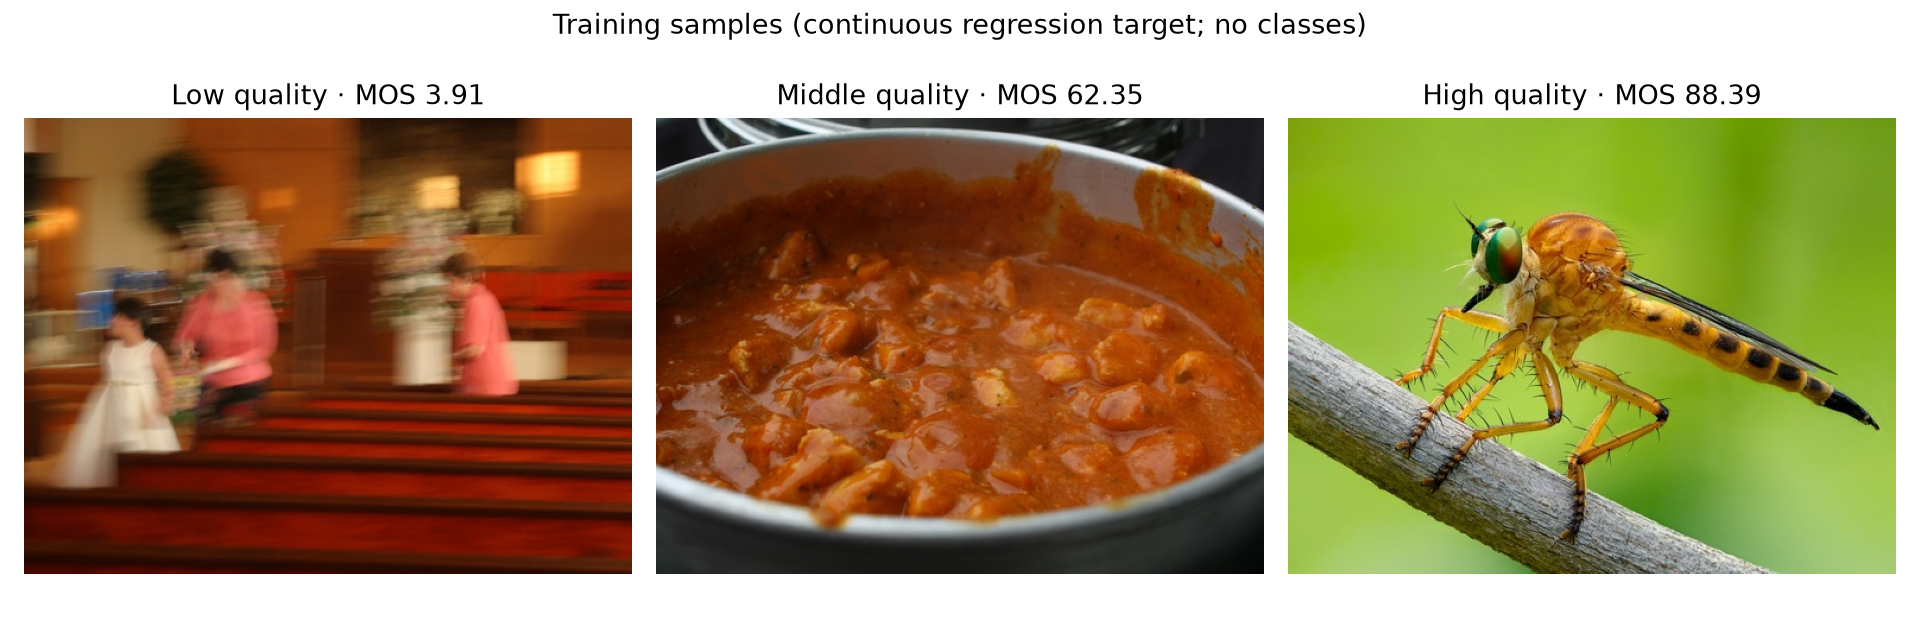

In [74]:
if not METADATA.is_file() or not IMAGES.is_dir():
    raise FileNotFoundError(
        f"Dataset paths do not exist. Kernel working directory: {Path.cwd()}\n"
        f"Metadata: {METADATA} (exists: {METADATA.is_file()})\n"
        f"Images: {IMAGES} (exists: {IMAGES.is_dir()})\n"
        "Rerun the setup cell above to refresh METADATA and IMAGES."
    )

bundle = prepare_data(METADATA, IMAGES, image_size=(64, 48), seed=SEED)
display(bundle.manifest.groupby("split").agg(images=("image_name", "size"), mean_mos=("MOS", "mean")))
print("Training RGB mean:", bundle.preprocessor.channel_mean.flatten().tolist())
print("Training RGB std:", bundle.preprocessor.channel_std.flatten().tolist())
print("Training MOS mean/std:", bundle.preprocessor.target_mean, bundle.preprocessor.target_std)
loaders = bundle.loaders(BATCH_SIZE, SEED)
x, y = next(iter(loaders["training"]))
print("Batch shapes:", x.shape, y.shape, "dtypes:", x.dtype, y.dtype)
SAMPLE_FIGURE = ROOT / "outputs/milestone2_preview/samples.png"
plot_samples(bundle, SAMPLE_FIGURE)
display(IPImage(filename=str(SAMPLE_FIGURE)))

## 2. Flexible MLP (12 points)

The shallow network has **256 and 128** hidden neurons. The first layer compresses
9,216 input pixels into a manageable representation; the second reduces capacity
to limit overfitting. The deeper network has exactly **256, 128, 64, 32, 16** hidden
neurons. Keeping the first two widths fixes the dominant input-layer capacity;
the additional tapered layers test added depth with a modest parameter increase.

Every hidden layer uses **ReLU**, an inexpensive nonlinearity without sigmoid's
positive-side saturation. Both networks end with **one linear output**, suitable
for a standardized continuous target (which can be negative). No softmax/sigmoid.
The builder accepts arbitrary hidden widths, output width, and activation class.


In [75]:
from src.mlp_models import MLP, SHALLOW, DEEP


In [76]:
input_dim = bundle.datasets["training"].tensors[0].shape[1]
for name, widths in [("shallow", SHALLOW), ("deep", DEEP)]:
    model = MLP(input_dim, widths)
    print(name, model)
    print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

shallow MLP(
  (network): Sequential(
    (0): Linear(in_features=9216, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)
Trainable parameters: 2392577
deep MLP(
  (network): Sequential(
    (0): Linear(in_features=9216, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): ReLU()
    (10): Linear(in_features=16, out_features=1, bias=True)
  )
)
Trainable parameters: 2403329


## 3. Required experiments (53 points)

**Losses:** MSE emphasizes large errors; MAE is less influenced by large errors;
Huber combines quadratic behavior near zero with linear tails (`delta=1`, one
training MOS standard deviation). All operate on standardized MOS.

**Regularization:** fixed explicit L2 strength **λ = 10⁻⁴** on weight matrices,
excluding biases: `objective = mean_data_loss + (λ/2) × Σ weight²`. Optimizer
weight decay is zero to apply the same defined penalty across optimizers.

**Optimizers:** SGD with momentum 0.9; RMSprop with alpha 0.99; Adam with default
betas (0.9, 0.999). Run the full **3×3** at learning rate **0.001**, then test
**0.0001, 0.0003, 0.001, 0.003** for the selected pair. Train the deep model with
that pair and the selected rate. Same seed, batch order, regularization and
30-epoch budget for every trial; restore each best validation checkpoint.

The execution cell calls the reusable experiment runner to perform the complete study. It prints progress after each trial
and saves each completed trial immediately. Each execution creates a fresh run
folder under `outputs/milestone2/`; `OUTPUT` points to that folder for the plots
and report below. Previous runs are preserved.


### Import the reusable experiment runner

The runner uses `train_model`, `Trial`, and evaluation helpers from
`src/mlp_training.py`. Model construction and training stay in the modules
so they can be imported by other notebooks or scripts.

In [77]:
from src.run_milestone2 import run_experiments


### Run the complete study

This runs all 14 models on your dataset. Results are saved and displayed below.

In [78]:
from datetime import datetime
from tempfile import mkdtemp

# Each execution gets a fresh folder, including reruns of this cell.
run_parent = ROOT / "outputs/milestone2"
run_parent.mkdir(parents=True, exist_ok=True)
OUTPUT = Path(mkdtemp(prefix=datetime.now().strftime("run_%Y%m%d_%H%M%S_"), dir=run_parent))
print("Saving this run to:", OUTPUT)

results = run_experiments(
    bundle, OUTPUT, epochs=EPOCHS, batch_size=BATCH_SIZE, l2=L2,
    seed=SEED, device=DEVICE, base_lr=1e-3,
    learning_rates=(1e-4, 3e-4, 1e-3, 3e-3), metadata_path=METADATA,
)

Saving this run to: /Users/mohamedkamaleldin/Documents/T261/ICS471/ics471-koniq10k/outputs/milestone2/run_20261009_193607_lzcfc2kf
Training grid_mse_sgd: mse, sgd, lr=0.001
  epoch=5; validation SROCC=0.4720; MAE=10.3642
Training grid_mse_rmsprop: mse, rmsprop, lr=0.001
  epoch=29; validation SROCC=0.4335; MAE=10.7889
Training grid_mse_adam: mse, adam, lr=0.001
  epoch=16; validation SROCC=0.4313; MAE=11.1203
Training grid_mae_sgd: mae, sgd, lr=0.001
  epoch=27; validation SROCC=0.4592; MAE=11.0359
Training grid_mae_rmsprop: mae, rmsprop, lr=0.001
  epoch=25; validation SROCC=0.4319; MAE=10.9980
Training grid_mae_adam: mae, adam, lr=0.001
  epoch=28; validation SROCC=0.4199; MAE=11.0983
Training grid_huber_sgd: huber, sgd, lr=0.001
  epoch=10; validation SROCC=0.4661; MAE=10.4012
Training grid_huber_rmsprop: huber, rmsprop, lr=0.001
  epoch=21; validation SROCC=0.4264; MAE=11.4116
Training grid_huber_adam: huber, adam, lr=0.001
  epoch=14; validation SROCC=0.4225; MAE=11.6748
Training 

### Complete 3×3 comparison — validation metrics

In [79]:
display(results["grid"])
display(results["grid"].pivot(index="loss", columns="optimizer", values="val_srocc"))

,run,loss,optimizer,lr,best_epoch,val_mae,val_rmse,val_srocc,val_loss,parameters,status
0,grid_mse_sgd,mse,sgd,0.001,5,10.364235,13.078497,0.472022,0.708916,2392577,ok
1,grid_mse_rmsprop,mse,rmsprop,0.001,29,10.788944,13.835402,0.433479,0.793345,2392577,ok
2,grid_mse_adam,mse,adam,0.001,16,11.120276,14.131967,0.431329,0.827721,2392577,ok
3,grid_mae_sgd,mae,sgd,0.001,27,11.035855,13.868639,0.459239,0.710469,2392577,ok
4,grid_mae_rmsprop,mae,rmsprop,0.001,25,10.998048,14.021661,0.431906,0.708035,2392577,ok
5,grid_mae_adam,mae,adam,0.001,28,11.098316,14.027684,0.419919,0.714491,2392577,ok
6,grid_huber_sgd,huber,sgd,0.001,10,10.401157,13.142266,0.466147,0.315266,2392577,ok
7,grid_huber_rmsprop,huber,rmsprop,0.001,21,11.411557,14.635425,0.426439,0.374010,2392577,ok
8,grid_huber_adam,huber,adam,0.001,14,11.674832,14.648696,0.422496,0.383774,2392577,ok


optimizer,adam,rmsprop,sgd
loss,,,
huber,0.422496,0.426439,0.466147
mae,0.419919,0.431906,0.459239
mse,0.431329,0.433479,0.472022


### Four learning rates — selected loss/optimizer

In [80]:
display(results["learning_rates"])

,run,loss,optimizer,lr,best_epoch,val_mae,val_rmse,val_srocc,val_loss,parameters,status
0,lr_0,mse,sgd,0.0001,25,10.498147,13.180994,0.458405,0.720071,2392577,ok
1,lr_1,mse,sgd,0.0003,10,10.608906,13.208949,0.460366,0.723128,2392577,ok
2,lr_2,mse,sgd,0.0010,5,10.364235,13.078497,0.472022,0.708916,2392577,ok
3,lr_3,mse,sgd,0.0030,3,10.410415,13.074619,0.476817,0.708495,2392577,ok


### Final shallow versus deep comparison — held-out test set

In [81]:
display(results["test"])
test = results["test"].set_index("network")
print("Deep minus shallow test SROCC:", test.loc["deep", "srocc"] - test.loc["shallow", "srocc"])
print("Deep minus shallow test MAE:", test.loc["deep", "mae"] - test.loc["shallow", "mae"])
print("Higher SROCC and lower MAE/RMSE are better. Do not retune using these test results.")

,network,hidden_layers,parameters,best_epoch,mae,rmse,srocc,loss
0,shallow,2,2392577,3,10.655842,13.485918,0.471036,0.753772
1,deep,5,2403329,7,10.451660,13.253496,0.479005,0.728014
2,training-mean baseline,0,0,0,12.511141,15.424191,NaN,NaN


Deep minus shallow test SROCC: 0.007969233852340274
Deep minus shallow test MAE: -0.2041821368574812
Higher SROCC and lower MAE/RMSE are better. Do not retune using these test results.


## 4. Required plots (10 points)

Both networks: training and validation **loss versus epoch**, and training and
validation **MAE/SROCC versus epoch**. Loss excludes L2 and is evaluated at the
same epoch-end model for both splits. MAE is converted back to original MOS
units. The selected checkpoint is marked by a dotted line.


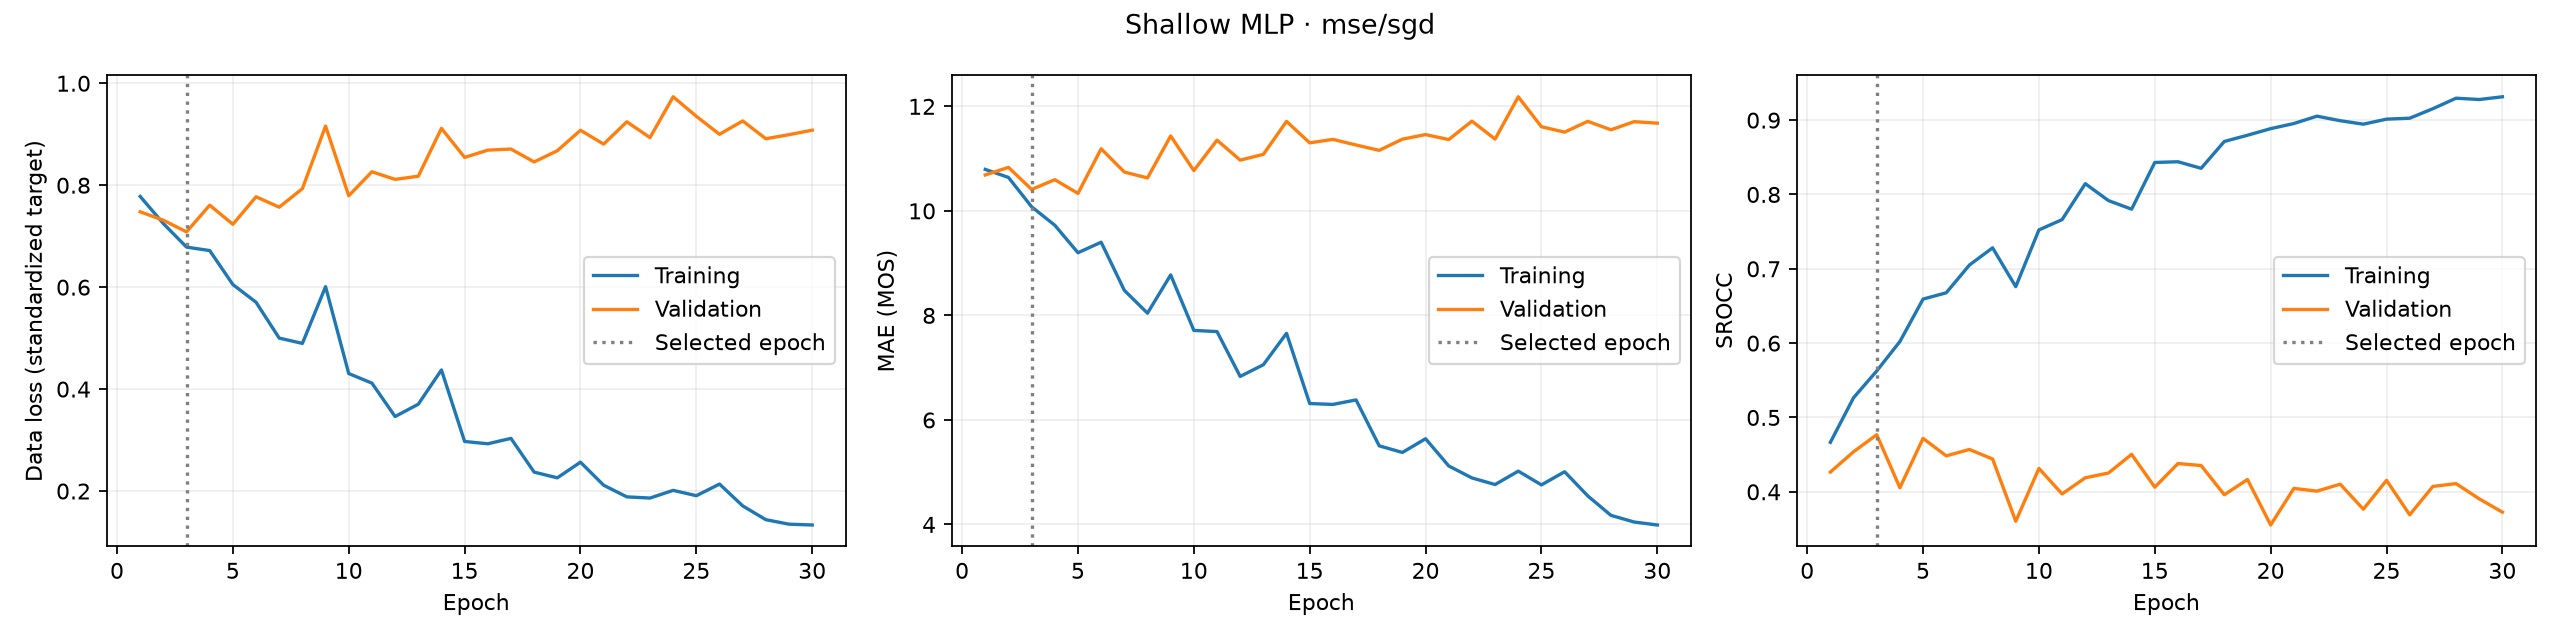

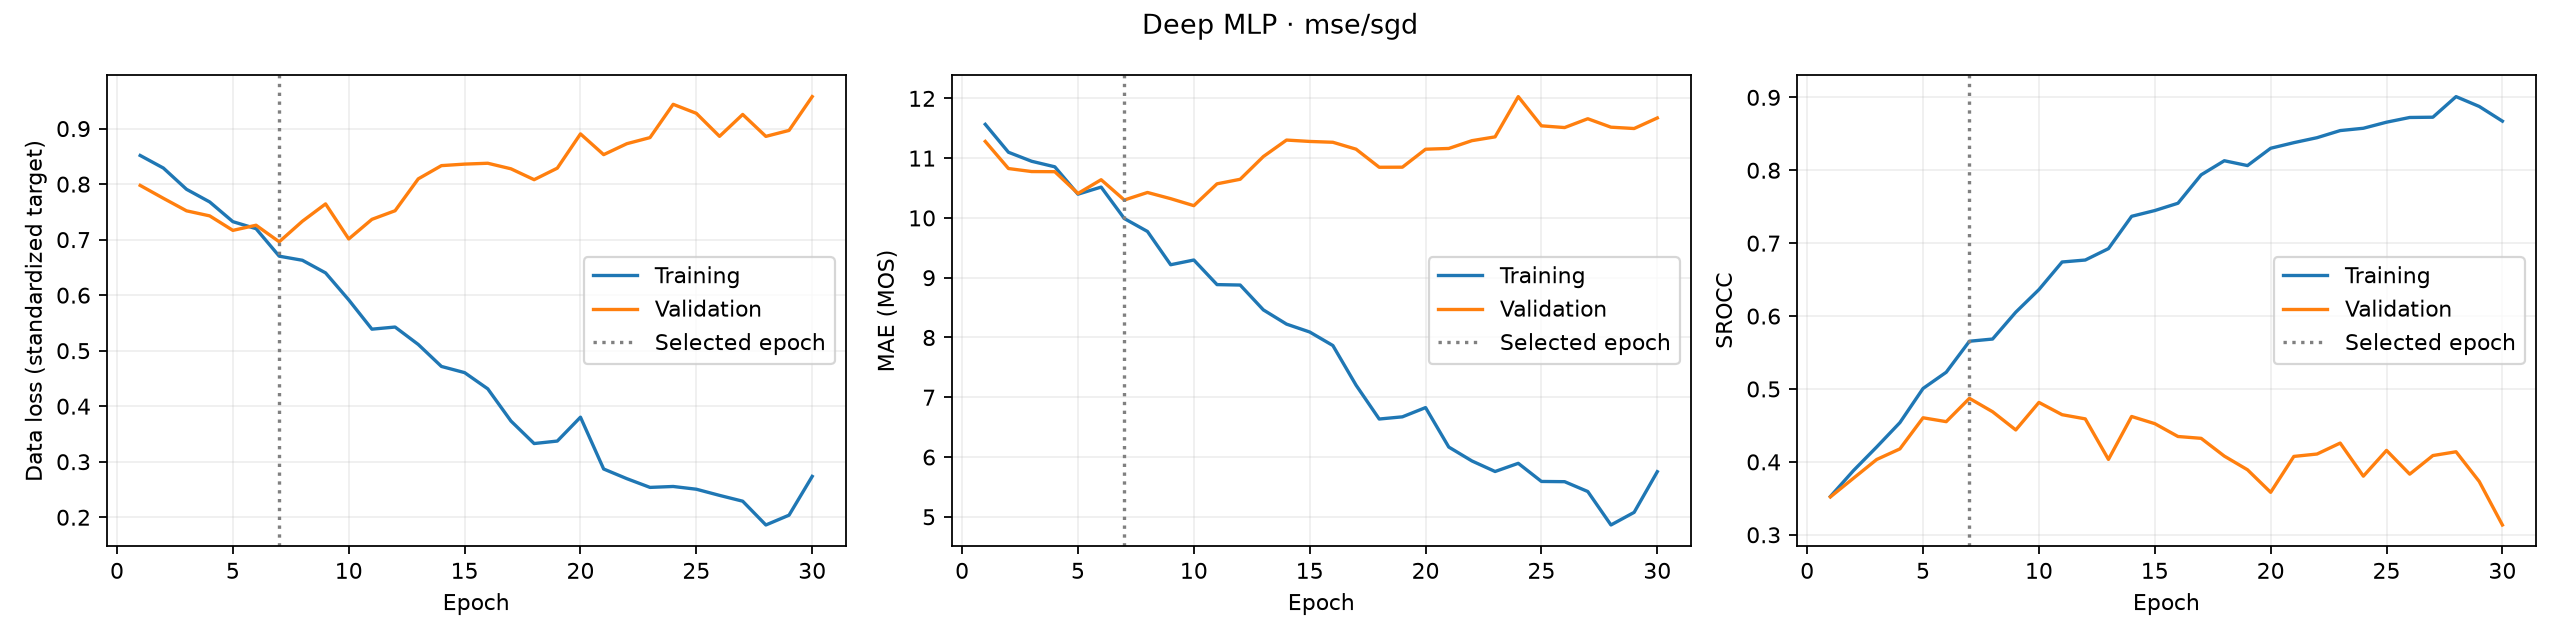

In [82]:
for name in ("shallow", "deep"):
    display(IPImage(filename=str(OUTPUT / f"{name}_curves.png")))

### Generated report and reproducibility artifacts

In [83]:
display(Markdown((OUTPUT / "report.md").read_text().split("## Required learning curves")[0]))
print("Saved tables, split manifest, settings, histories, predictions, and checkpoints:", OUTPUT)

# Milestone 2: KonIQ-10k MLP regression

## Protocol
Seed 42; 30 epochs per trial; batch size 64; device cpu.
Split policy: official test held out; remaining pool split 80/20.
RGB images resize to (64, 48), scale to [0,1], and use training-only
channel standardization. MOS targets use training-only mean/std normalization.
No rating-derived metadata is used as input. There are no classification labels;
stratification and class encoding are inapplicable. Samples span training MOS ranks.

Shallow hidden widths: (256, 128); deep hidden widths: (256, 128, 64, 32, 16). ReLU hidden
activations provide inexpensive nonlinearities; the linear scalar output predicts
standardized MOS without clipping. The taper limits model size. Resizing reduces
compute but can remove subtle quality artifacts, a limitation of this baseline.

Explicit L2 strength is **0.0001**: objective = mean data loss + lambda/2 times
the sum of squared weights (biases excluded). Optimizer weight decay is zero.
MSE emphasizes large errors; MAE reduces their influence; Huber (delta=1 in
standardized MOS) combines quadratic and linear behavior. SGD momentum=0.9;
RMSprop alpha=0.99; Adam uses PyTorch defaults. All trials use the same splits,
initialization seed, batch order, epoch budget, and regularization.

## 3 × 3 loss/optimizer comparison
Base learning rate: 0.001. Epochs and combinations are chosen by maximum
validation SROCC, then minimum RMSE for ties. Loss magnitudes across different
loss functions are not directly comparable. Undefined SROCC ranks last.

| run | loss | optimizer | lr | best_epoch | val_mae | val_rmse | val_srocc | val_loss | parameters | status |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| grid_mse_sgd | mse | sgd | 0.001 | 5 | 10.3642 | 13.0785 | 0.472022 | 0.708916 | 2392577 | ok |
| grid_mse_rmsprop | mse | rmsprop | 0.001 | 29 | 10.7889 | 13.8354 | 0.433479 | 0.793345 | 2392577 | ok |
| grid_mse_adam | mse | adam | 0.001 | 16 | 11.1203 | 14.132 | 0.431329 | 0.827721 | 2392577 | ok |
| grid_mae_sgd | mae | sgd | 0.001 | 27 | 11.0359 | 13.8686 | 0.459239 | 0.710469 | 2392577 | ok |
| grid_mae_rmsprop | mae | rmsprop | 0.001 | 25 | 10.998 | 14.0217 | 0.431906 | 0.708035 | 2392577 | ok |
| grid_mae_adam | mae | adam | 0.001 | 28 | 11.0983 | 14.0277 | 0.419919 | 0.714491 | 2392577 | ok |
| grid_huber_sgd | huber | sgd | 0.001 | 10 | 10.4012 | 13.1423 | 0.466147 | 0.315266 | 2392577 | ok |
| grid_huber_rmsprop | huber | rmsprop | 0.001 | 21 | 11.4116 | 14.6354 | 0.426439 | 0.37401 | 2392577 | ok |
| grid_huber_adam | huber | adam | 0.001 | 14 | 11.6748 | 14.6487 | 0.422496 | 0.383774 | 2392577 | ok |

## Four learning rates
Selected pair: **mse + sgd**.

| run | loss | optimizer | lr | best_epoch | val_mae | val_rmse | val_srocc | val_loss | parameters | status |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| lr_0 | mse | sgd | 0.0001 | 25 | 10.4981 | 13.181 | 0.458405 | 0.720071 | 2392577 | ok |
| lr_1 | mse | sgd | 0.0003 | 10 | 10.6089 | 13.2089 | 0.460366 | 0.723128 | 2392577 | ok |
| lr_2 | mse | sgd | 0.001 | 5 | 10.3642 | 13.0785 | 0.472022 | 0.708916 | 2392577 | ok |
| lr_3 | mse | sgd | 0.003 | 3 | 10.4104 | 13.0746 | 0.476817 | 0.708495 | 2392577 | ok |

Selected learning rate: **0.003**.

## Held-out test comparison
The same selected loss, optimizer and learning rate are used for both networks.
Each network restores its own best validation epoch. MAE/RMSE are in original
MOS units. The constant training-mean baseline has undefined SROCC by definition.

| network | hidden_layers | parameters | best_epoch | mae | rmse | srocc | loss |
| --- | --- | --- | --- | --- | --- | --- | --- |
| shallow | 2 | 2392577 | 3 | 10.6558 | 13.4859 | 0.471036 | 0.753772 |
| deep | 5 | 2403329 | 7 | 10.4517 | 13.2535 | 0.479005 | 0.728014 |
| training-mean baseline | 0 | 0 | 0 | 12.5111 | 15.4242 | nan | nan |

Deep minus shallow validation SROCC: 0.010323.
Deep minus shallow test SROCC: 0.007969.
Deep minus shallow test MAE: -0.204182.
Positive SROCC differences favor deep; negative MAE differences favor deep.
These are single-seed results, not evidence of statistical significance. Test
results are reported after selection and must not be used to retune this study.



Saved tables, split manifest, settings, histories, predictions, and checkpoints: /Users/mohamedkamaleldin/Documents/T261/ICS471/ics471-koniq10k/outputs/milestone2/run_20261009_193607_lzcfc2kf


### Limitations and sources

A flattened pixel MLP does not explicitly exploit spatial locality, and resizing
may remove blur/noise cues. Depth alone need not improve generalization. Interpret
the test comparison as one controlled run. Repeating seeds would estimate
variability, but is outside the required comparison.

- [Authors' KonIQ metadata](https://github.com/subpic/koniq/tree/master/metadata)
- [PyTorch HuberLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.HuberLoss.html)
